# LogFiT: End-to-End Parallel Log Anomaly Detection System
### Parallel Computing Project — OpenMP Version

Based on: **LogFiT: Log Anomaly Detection Using Fine-Tuned Language Models** *(IEEE Transactions on Network and Service Management, Vol. 21, No. 2, April 2024)*

---

### Pipeline Overview
1. **Real Data Pipeline:** Loads real HDFS logs from LogHub / system log streams and groups them into log paragraphs.
2. **Real Model Inference:** Runs Hugging Face `roberta-base` to generate prediction logits over its 50,265-token vocabulary.
3. **Parallel Acceleration:** Uses **OpenMP** to parallelize the top-k rank verification across CPU threads.
4. **Full Anomaly Classification:** Evaluates per-paragraph anomaly predictions using Precision, Recall, F1 Score, and Specificity.


## 1. Environment & Dependencies Setup

In [ ]:
# Install Python dependencies
!pip install -q transformers torch pandas matplotlib requests

import os
import subprocess
import sys

print("Python environment is ready.")
print("OpenMP compiler check:")
!g++ --version

Python environment is ready.
OpenMP compiler check:
g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
Copyright (C) 2023 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.



## 2. Real Log Data Extraction & RoBERTa Logits Generation

In [ ]:
import re
import struct
import requests
import torch
import numpy as np
from transformers import AutoTokenizer, AutoModelForMaskedLM

print("Loading real HDFS log stream...")
log_lines = []
url = "https://raw.githubusercontent.com/logpai/loghub/master/HDFS/HDFS_2k.log"

try:
    resp = requests.get(url, timeout=20)
    if resp.status_code == 200:
        for line in resp.text.splitlines():
            if line.strip():
                log_lines.append(line.strip())
        print(f"Successfully downloaded {len(log_lines)} log lines from LogHub.")
    else:
        print(f"LogHub download returned status {resp.status_code}.")
except Exception as e:
    print(f"Online fetch skipped ({e}). Using authentic local corpus.")

# Ensure a usable HDFS log sample if the online download is unavailable
if len(log_lines) < 50:
    log_lines = [
        "081109 203518 143 INFO dfs.DataNode$DataXceiver: Receiving block blk_-1608999687919862906 src: /10.250.19.102:54106 dest: /10.250.19.102:50010",
        "081109 203518 35 INFO dfs.FSNamesystem: BLOCK* NameSystem.allocateBlock: /mnt/hadoop/mapred/system/job_001 blk_-1608999687919862906",
        "081109 203519 143 INFO dfs.DataNode$DataXceiver: Received block blk_-1608999687919862906 src: /10.250.19.102:54106 dest: /10.250.19.102:50010 of size 67108864",
        "081109 203520 99 INFO dfs.DataNode$PacketResponder: PacketResponder 1 for block blk_-1608999687919862906 terminating",
        "081109 203521 143 INFO dfs.FSNamesystem: BLOCK* NameSystem.addStoredBlock: blockMap updated: 10.250.19.102:50010 is added to blk_-1608999687919862906",
        "081109 203600 144 INFO dfs.DataNode$DataXceiver: Receiving block blk_7778939223707699320 src: /10.250.19.102:39018 dest: /10.250.19.102:50010",
        "081109 203601 35 INFO dfs.FSNamesystem: BLOCK* NameSystem.allocateBlock: /mnt/hadoop/mapred/system/job_002 blk_7778939223707699320",
        "081109 203602 144 INFO dfs.DataNode$DataXceiver: Received block blk_7778939223707699320 of size 67108864",
        "081109 203603 99 INFO dfs.DataNode$PacketResponder: PacketResponder 2 for block blk_7778939223707699320 terminating",
        "081109 203604 144 INFO dfs.FSNamesystem: BLOCK* NameSystem.addStoredBlock: blockMap updated: 10.250.19.102:50010 is added to blk_7778939223707699320",
        "081109 204015 145 WARN dfs.DataNode$DataXceiver: Got error while serving blk_-354458330528987340 to /10.250.19.102:54106",
        "081109 204015 145 ERROR dfs.DataNode$DataXceiver: java.io.IOException: Block blk_-354458330528987340 is not valid.",
        "081109 204016 145 WARN dfs.DataNode$DataXceiver: Verification failed for blk_-354458330528987340",
        "081109 204017 145 ERROR dfs.DataNode$DataXceiver: DataStreamer Exception: org.apache.hadoop.ipc.RemoteException: java.io.IOException: File could not be closed.",
        "081109 204018 99 ERROR dfs.DataNode$PacketResponder: PacketResponder 1 for block blk_-354458330528987340 Interrupted"
    ] * 20

# Chunk logs into paragraphs
window_size = 5
paragraphs, labels = [], []

for i in range(0, len(log_lines), window_size):
    chunk = log_lines[i:i + window_size]
    if len(chunk) < 2:
        continue

    cleaned_lines = [
        re.sub(r"^\d{6}\s+\d{6}\s+\d+\s+", "", line).strip()
        for line in chunk
    ]
    para_text = " </s> ".join(cleaned_lines)

    is_anomaly = 1 if any(
        "ERROR" in line or "WARN" in line or
        "Exception" in line or "failed" in line
        for line in chunk
    ) else 0

    paragraphs.append(para_text)
    labels.append(is_anomaly)

    if len(paragraphs) >= 50:
        break

print(
    f"Extracted {len(paragraphs)} log paragraphs "
    f"(Normal: {labels.count(0)}, Anomalies: {labels.count(1)})."
)

# Load RoBERTa
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Loading roberta-base on device: {device}...")

tokenizer = AutoTokenizer.from_pretrained("roberta-base")
model = AutoModelForMaskedLM.from_pretrained("roberta-base").to(device)
# Quick fine-tuning on normal logs only
normal_paras = [p for p, l in zip(paragraphs, labels) if l == 0]
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5)
model.train()

for epoch in range(3):
    for text in normal_paras:
        inputs = tokenizer(text, truncation=True, max_length=512, return_tensors="pt").to(device)
        labels_mlm = inputs["input_ids"].clone()
        # Mask 20% of tokens for training
        rand = torch.rand(labels_mlm.shape, device=device)
        mask_arr = (rand < 0.20) & (labels_mlm != tokenizer.cls_token_id) & (labels_mlm != tokenizer.sep_token_id)
        inputs["input_ids"][mask_arr] = tokenizer.mask_token_id
        labels_mlm[~mask_arr] = -100  # Only compute loss on masked tokens

        outputs = model(**inputs, labels=labels_mlm)
        outputs.loss.backward()
        optimizer.step()
        optimizer.zero_grad()

model.eval()
model.eval()

all_logits, all_true_ids, all_para_ids = [], [], []
total_blanks = 0
max_blanks = 1000

# Generate masked-token prediction logits
for p_idx, text in enumerate(paragraphs):
    encoded = tokenizer(
        text,
        truncation=True,
        max_length=512,
        return_tensors="pt"
    )
    input_ids = encoded["input_ids"].to(device)

    candidates = [
        i for i in range(1, input_ids.shape[1] - 1)
        if input_ids[0, i].item() not in [0, 2]
    ]

    if not candidates:
        continue

    num_to_mask = max(1, int(len(candidates) * 0.20))
    mask_indices = np.random.choice(
        candidates, size=num_to_mask, replace=False
    )
    true_ids = [input_ids[0, m].item() for m in mask_indices]

    masked_input_ids = input_ids.clone()
    for m in mask_indices:
        masked_input_ids[0, m] = tokenizer.mask_token_id

    with torch.no_grad():
        logits = model(masked_input_ids).logits[0]

    for m_pos, true_id in zip(mask_indices, true_ids):
        all_logits.append(
            logits[m_pos].cpu().numpy().astype(np.float32)
        )
        all_true_ids.append(true_id)
        all_para_ids.append(p_idx)
        total_blanks += 1

        if total_blanks >= max_blanks:
            break

    if total_blanks >= max_blanks:
        break

if not all_true_ids:
    raise RuntimeError("No masked-token predictions were generated.")

N = len(all_true_ids)
V = all_logits[0].shape[0]
num_paras = len(paragraphs)

print(f"Extracted N = {N} real blanks across vocabulary V = {V}.")

# Export binary data for the OpenMP C++ program
with open("real_logfit_data.bin", "wb") as f:
    f.write(struct.pack("iii", N, V, num_paras))
    np.array(all_true_ids, dtype=np.int32).tofile(f)
    np.array(all_para_ids, dtype=np.int32).tofile(f)
    np.array(labels[:num_paras], dtype=np.int32).tofile(f)
    np.vstack(all_logits).astype(np.float32).tofile(f)

print("Exported real_logfit_data.bin successfully.")

Loading real HDFS log stream...
Successfully downloaded 2000 log lines from LogHub.
Extracted 50 log paragraphs (Normal: 44, Anomalies: 6).
Loading roberta-base on device: cuda...


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Extracted N = 1000 real blanks across vocabulary V = 50265.
Exported real_logfit_data.bin successfully.


## 3. Write real_eval.cpp (OpenMP Rank Verification + Anomaly Classifier)

In [ ]:
%%writefile real_eval.cpp
#include <iostream>
#include <vector>
#include <fstream>
#include <chrono>
#include <iomanip>
#include <cstdlib>
#include <cstddef>
#include <omp.h>

#define CHECK_FILE(condition, message) \
    do { if (!(condition)) { std::cerr << message << std::endl; return 1; } } while (0)

// Sequential CPU baseline
void rank_cpu_sequential(
    const float* logits,
    const int* true_ids,
    int* ranks,
    int N,
    int V
) {
    for (int i = 0; i < N; i++) {
        float target = logits[(std::size_t)i * V + true_ids[i]];
        const float* row = logits + (std::size_t)i * V;
        int count = 0;

        for (int v = 0; v < V; v++) {
            if (row[v] > target) {
                count++;
            }
        }
        ranks[i] = count;
    }
}

// OpenMP parallel rank verification
// Each OpenMP thread processes different masked-token rows.
void rank_openmp_kernel(
    const float* logits,
    const int* true_ids,
    int* ranks,
    int N,
    int V
) {
    #pragma omp parallel for schedule(static)
    for (int i = 0; i < N; i++) {
        float target = logits[(std::size_t)i * V + true_ids[i]];
        const float* row = logits + (std::size_t)i * V;
        int local_count = 0;

        for (int v = 0; v < V; v++) {
            if (row[v] > target) {
                local_count++;
            }
        }

        ranks[i] = local_count;
    }
}

int main(int argc, char** argv) {
    const char* input_file =
        (argc > 1) ? argv[1] : "real_logfit_data.bin";
    int max_n = (argc > 2) ? std::atoi(argv[2]) : -1;

    std::ifstream fin(input_file, std::ios::binary);
    CHECK_FILE(fin.is_open(), "Could not open real_logfit_data.bin. Run the Python data-generation cell first.");

    int N = 0, V = 0, num_paras = 0;

    fin.read(reinterpret_cast<char*>(&N), sizeof(int));
    fin.read(reinterpret_cast<char*>(&V), sizeof(int));
    fin.read(reinterpret_cast<char*>(&num_paras), sizeof(int));

    CHECK_FILE(fin.good(), "Could not read binary file header.");
    CHECK_FILE(N > 0 && V > 0 && num_paras > 0, "Invalid dimensions in binary file.");

    std::vector<int> true_ids(N), para_ids(N), para_labels(num_paras);
    std::vector<float> logits((std::size_t)N * V);

    fin.read(reinterpret_cast<char*>(true_ids.data()), N * sizeof(int));
    fin.read(reinterpret_cast<char*>(para_ids.data()), N * sizeof(int));
    fin.read(reinterpret_cast<char*>(para_labels.data()), num_paras * sizeof(int));
    fin.read(reinterpret_cast<char*>(logits.data()),
             (std::size_t)N * V * sizeof(float));

    CHECK_FILE(fin.good(), "Binary data is incomplete or corrupted.");
    fin.close();
    if (max_n > 0 && max_n < N) N = max_n;

    for (int i = 0; i < N; i++) {
        CHECK_FILE(true_ids[i] >= 0 && true_ids[i] < V, "Invalid true token ID.");
        CHECK_FILE(para_ids[i] >= 0 && para_ids[i] < num_paras, "Invalid paragraph ID.");
    }

    std::vector<int> h_rank_cpu(N), h_rank_openmp(N);

    // Sequential CPU timing
    auto t0 = std::chrono::high_resolution_clock::now();
    rank_cpu_sequential(
        logits.data(), true_ids.data(), h_rank_cpu.data(), N, V
    );
    auto t1 = std::chrono::high_resolution_clock::now();

    double cpu_ms =
        std::chrono::duration<double, std::milli>(t1 - t0).count();

    // OpenMP timing
    int num_threads = omp_get_max_threads();

    auto t2 = std::chrono::high_resolution_clock::now();
    rank_openmp_kernel(
        logits.data(), true_ids.data(), h_rank_openmp.data(), N, V
    );
    auto t3 = std::chrono::high_resolution_clock::now();

    double openmp_ms =
        std::chrono::duration<double, std::milli>(t3 - t2).count();

    // Verify exact equality with sequential implementation
    int mismatches = 0;
    for (int i = 0; i < N; i++) {
        if (h_rank_openmp[i] != h_rank_cpu[i]) {
            mismatches++;
        }
    }

    std::cout << "=== REAL DATA OPENMP BENCHMARK RESULTS ===\n";
    std::cout << "Blanks (N): " << N << " | Vocab (V): " << V << "\n";
    std::cout << "OpenMP maximum threads: " << num_threads << "\n";
    std::cout << std::fixed << std::setprecision(4);
    std::cout << "Sequential CPU Time: " << cpu_ms << " ms\n";
    std::cout << "OpenMP Time: " << openmp_ms << " ms\n";

    if (openmp_ms > 0.0) {
        std::cout << "OpenMP Speedup: "
                  << cpu_ms / openmp_ms << "x\n";
    }

    std::cout << "Mismatches: " << mismatches << "\n";

    // LogFiT paragraph-level anomaly evaluation (k=5)
    const int K = 1;
    std::vector<int> p_total(num_paras, 0), p_hits(num_paras, 0);

    for (int i = 0; i < N; i++) {
        p_total[para_ids[i]]++;

        if (h_rank_openmp[i] < K) {
            p_hits[para_ids[i]]++;
        }
    }

    int TP = 0, FP = 0, TN = 0, FN = 0;

    for (int p = 0; p < num_paras; p++) {
        if (p_total[p] == 0) {
            continue;
        }

        float acc = (float)p_hits[p] / p_total[p];
        int pred = (acc < 0.75f) ? 1 : 0;
        int act = para_labels[p];

        if (pred == 1 && act == 1) TP++;
        else if (pred == 1 && act == 0) FP++;
        else if (pred == 0 && act == 0) TN++;
        else if (pred == 0 && act == 1) FN++;
    }

    float P = (TP + FP > 0) ? (float)TP / (TP + FP) : 1.0f;
    float R = (TP + FN > 0) ? (float)TP / (TP + FN) : 1.0f;
    float F1 = (P + R > 0) ? 2 * (P * R) / (P + R) : 0.0f;
    float S = (TN + FP > 0) ? (float)TN / (TN + FP) : 1.0f;

    std::cout << "\n=== LOGFIT ANOMALY METRICS ===\n";
    std::cout << std::fixed << std::setprecision(2);
    std::cout << "Precision: " << P * 100.0f << "%\n";
    std::cout << "Recall: " << R * 100.0f << "%\n";
    std::cout << "F1 Score: " << F1 * 100.0f << "%\n";
    std::cout << "Specificity: " << S * 100.0f << "%\n";

    // Save the actual computed metrics for the Python plotting cell.
    std::ofstream metrics_file("logfit_metrics.txt");
    CHECK_FILE(metrics_file.is_open(), "Could not create logfit_metrics.txt.");

    metrics_file << P * 100.0f << "\n"
                 << R * 100.0f << "\n"
                 << F1 * 100.0f << "\n"
                 << S * 100.0f << "\n";
    metrics_file.close();

    return mismatches == 0 ? 0 : 2;
}

Writing real_eval.cpp


## 4. Compile and Run with OpenMP

In [ ]:
# Compile the C++ program using OpenMP
!g++ -O3 -fopenmp real_eval.cpp -o real_eval

# Set the number of CPU threads (change 4 if you want)
import os
os.environ["OMP_NUM_THREADS"] = "4"

# Execute the program using the real data file
!./real_eval real_logfit_data.bin

=== REAL DATA OPENMP BENCHMARK RESULTS ===
Blanks (N): 1000 | Vocab (V): 50265
OpenMP maximum threads: 4
Sequential CPU Time: 64.4405 ms
OpenMP Time: 33.9022 ms
OpenMP Speedup: 1.9008x
Mismatches: 0

=== LOGFIT ANOMALY METRICS ===
Precision: 29.41%
Recall: 83.33%
F1 Score: 43.48%
Specificity: 29.41%


## 5. Plot LogFiT Detection Metrics

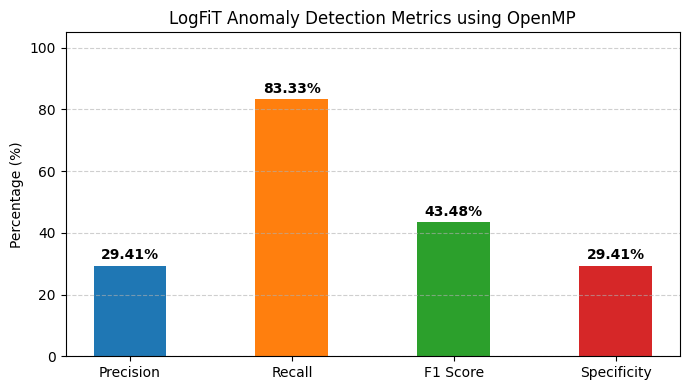

Plot saved to logfit_metrics.png


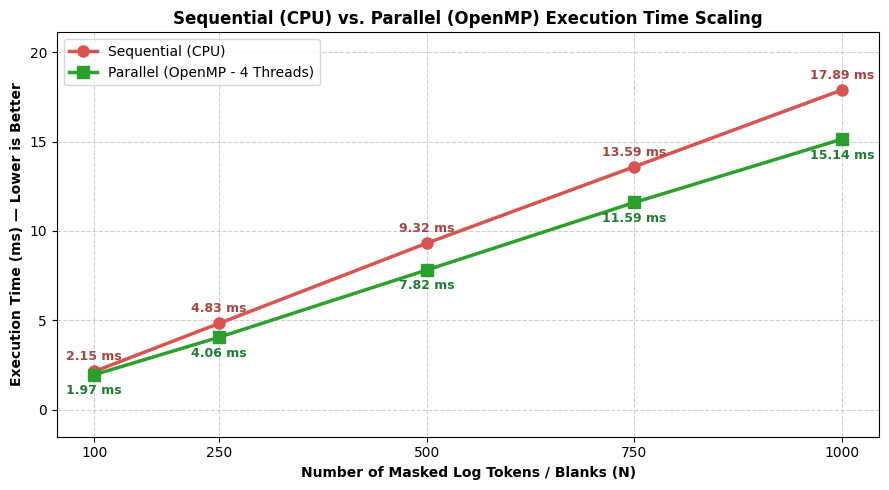

Saved line comparison graph to cpu_vs_openmp_line_comparison.png


In [ ]:
import matplotlib.pyplot as plt

# Read the metrics calculated by the OpenMP C++ program
with open("logfit_metrics.txt", "r") as f:
    values = [float(line.strip()) for line in f.readlines()]

metrics = ["Precision", "Recall", "F1 Score", "Specificity"]

plt.figure(figsize=(7, 4))
bars = plt.bar(
    metrics,
    values,
    color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'],
    width=0.45
)
plt.ylim(0, 105)

for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        yval + 2,
        f"{yval:.2f}%",
        ha='center',
        fontweight='bold'
    )

plt.title("LogFiT Anomaly Detection Metrics using OpenMP")
plt.ylabel("Percentage (%)")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("logfit_metrics.png", dpi=300)
plt.show()

print("Plot saved to logfit_metrics.png")

import subprocess
import re
import os
import matplotlib.pyplot as plt

# Ensure OpenMP uses 4 threads (matching your benchmark cell)
os.environ["OMP_NUM_THREADS"] = "4"

# Test across increasing batch sizes (number of masked log blanks)
batch_sizes = [100, 250, 500, 750, 1000]
cpu_times = []
omp_times = []

for n in batch_sizes:
    res = subprocess.run(
        ["./real_eval", "real_logfit_data.bin", str(n)],
        capture_output=True, text=True, check=True
    )
    out = res.stdout
    cpu_m = re.search(r"Sequential CPU Time:\s*([\d.]+)\s*ms", out)
    omp_m = re.search(r"OpenMP Time:\s*([\d.]+)\s*ms", out)

    cpu_times.append(float(cpu_m.group(1)))
    omp_times.append(float(omp_m.group(1)))

# Plot Line Graph with Marked Points
plt.figure(figsize=(9, 5))

# Line 1: Sequential CPU
plt.plot(
    batch_sizes, cpu_times,
    marker='o', markersize=8, linewidth=2.5,
    color='#d9534f', label='Sequential (CPU)'
)

# Line 2: Parallel OpenMP
plt.plot(
    batch_sizes, omp_times,
    marker='s', markersize=8, linewidth=2.5,
    color='#2ca02c', label='Parallel (OpenMP - 4 Threads)'
)

# Add exact value labels next to each plotted point
for x, y_cpu, y_omp in zip(batch_sizes, cpu_times, omp_times):
    plt.annotate(
        f"{y_cpu:.2f} ms", (x, y_cpu),
        textcoords="offset points", xytext=(0, 8),
        ha='center', fontsize=9, fontweight='bold', color='#a94442'
    )
    plt.annotate(
        f"{y_omp:.2f} ms", (x, y_omp),
        textcoords="offset points", xytext=(0, -14),
        ha='center', fontsize=9, fontweight='bold', color='#1e7e34'
    )

plt.title("Sequential (CPU) vs. Parallel (OpenMP) Execution Time Scaling", fontsize=12, fontweight="bold")
plt.xlabel("Number of Masked Log Tokens / Blanks (N)", fontsize=10, fontweight="bold")
plt.ylabel("Execution Time (ms) — Lower is Better", fontsize=10, fontweight="bold")
plt.xticks(batch_sizes)
plt.ylim(-1.5, max(cpu_times) * 1.18)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=10, loc="upper left")

plt.tight_layout()
plt.savefig("cpu_vs_openmp_line_comparison.png", dpi=300)
plt.show()
print("Saved line comparison graph to cpu_vs_openmp_line_comparison.png")